In [15]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Netflix dataset
url = "https://huggingface.co/datasets/jason1966/algozee_netflix-content-analysis/resolve/main/netflix_titles.csv"

df = pd.read_csv(url)

# Display the first five rows
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [16]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical Summary:")
df.describe(include="all")

Dataset Shape: (8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values:
show_id            0
type       

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [17]:
# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values in important text columns
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Not Rated")
df["duration"] = df["duration"].fillna("Unknown")

# Remove rows with missing essential information
df.dropna(subset=["date_added", "release_year", "listed_in"], inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display the cleaned dataset
print("\nCleaned Dataset Shape:", df.shape)
df.head()

Missing values before cleaning:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Missing values after cleaning:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Cleaned Dataset Shape: (8797, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Content Type Distribution:
type
Movie      6131
TV Show    2666
Name: count, dtype: int64


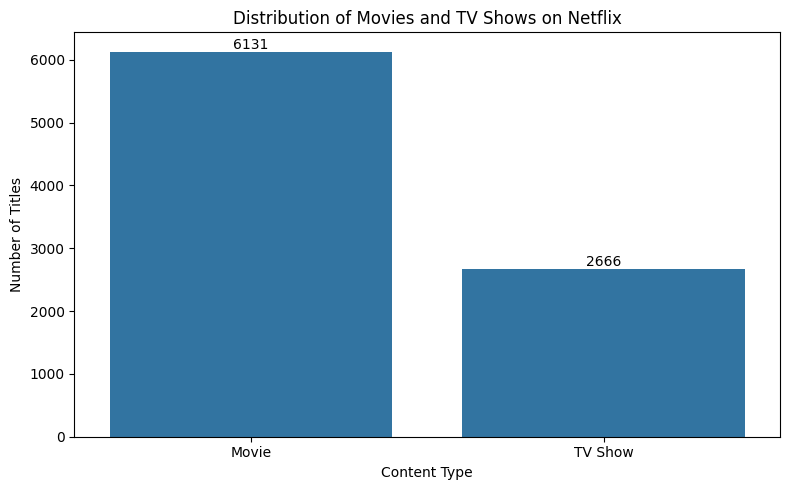

In [18]:
# Count movies and TV shows
content_counts = df["type"].value_counts()

print("Content Type Distribution:")
print(content_counts)

# Create a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=content_counts.index, y=content_counts.values)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

# Display values above the bars
for i, value in enumerate(content_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

Titles released in the most recent years:
release_year
2012     236
2013     287
2014     352
2015     558
2016     901
2017    1032
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


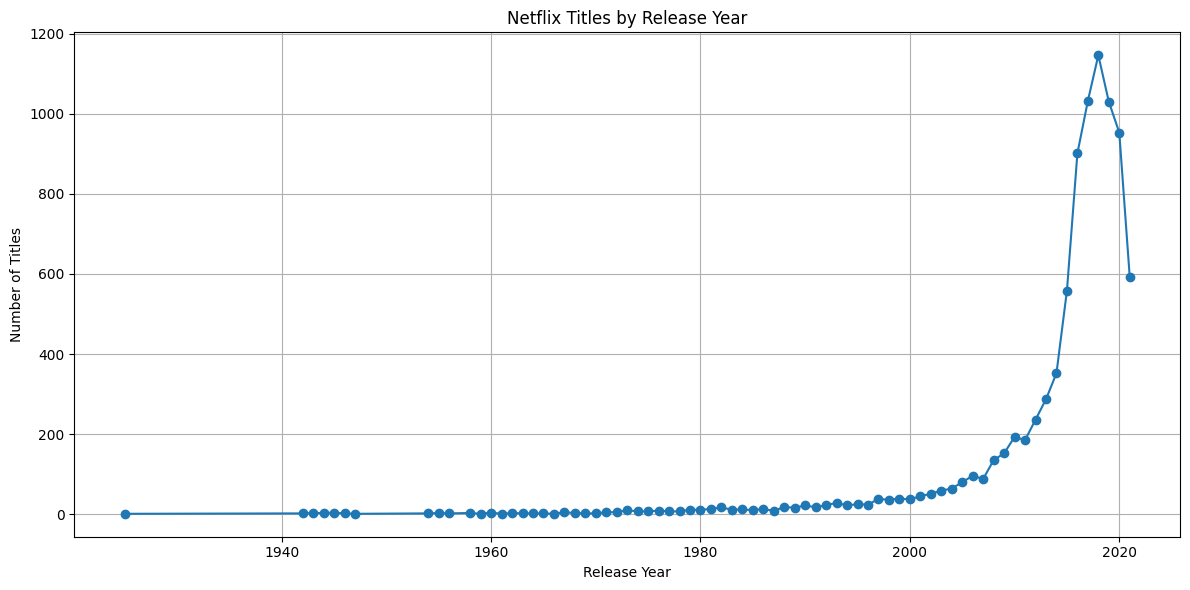

In [19]:
# Count titles released in each year
year_counts = df["release_year"].value_counts().sort_index()

# Display the most recent 10 years
print("Titles released in the most recent years:")
print(year_counts.tail(10))

# Create a line chart
plt.figure(figsize=(12, 6))

plt.plot(year_counts.index, year_counts.values, marker="o")

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.tight_layout()
plt.show()

Top 10 Genres on Netflix:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1350
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


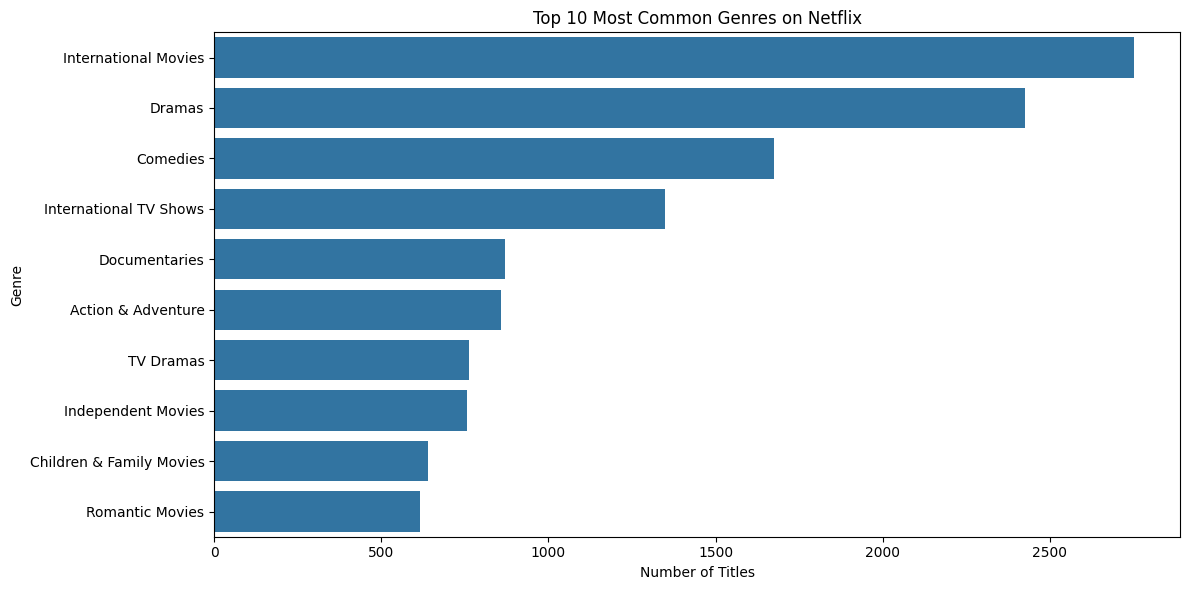

In [20]:
# Split genres and count each genre
genre_counts = (
    df["listed_in"]
    .str.split(", ")
    .explode()
    .value_counts()
)

# Display the top 10 genres
top_genres = genre_counts.head(10)

print("Top 10 Genres on Netflix:")
print(top_genres)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Most Common Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

Top 10 Content-Producing Countries:
country
United States     3683
India             1046
United Kingdom     803
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


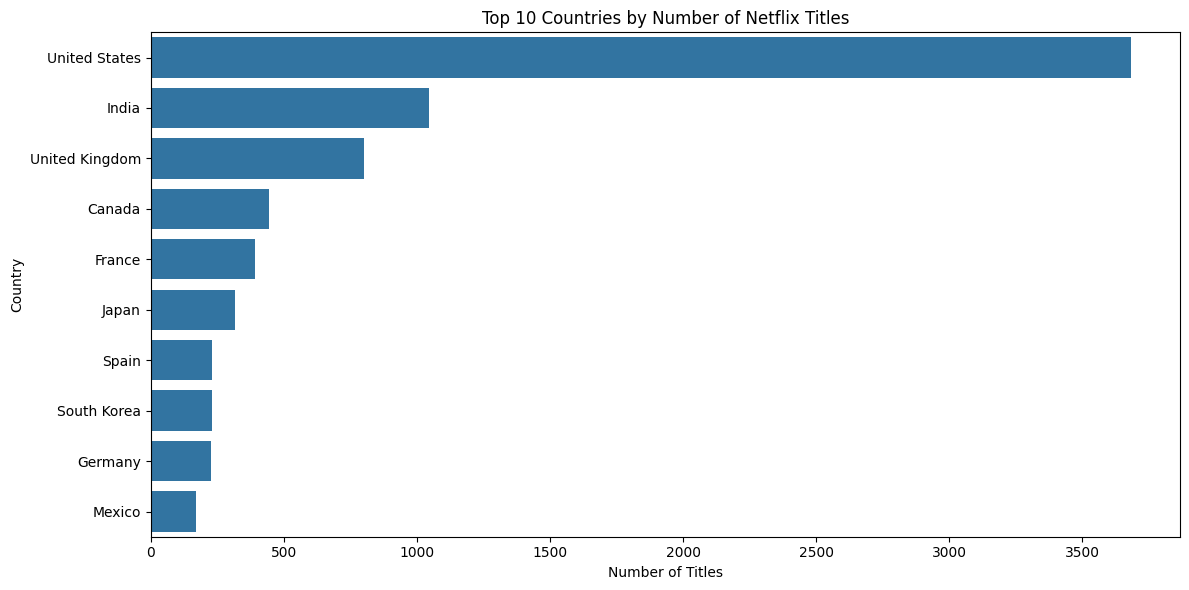

In [21]:
# Split country names and count each country
country_counts = (
    df[df["country"] != "Unknown"]["country"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

# Select the top 10 countries
top_countries = country_counts.head(10)

# Display the results
print("Top 10 Content-Producing Countries:")
print(top_countries)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

Top 10 Netflix Content Ratings:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64


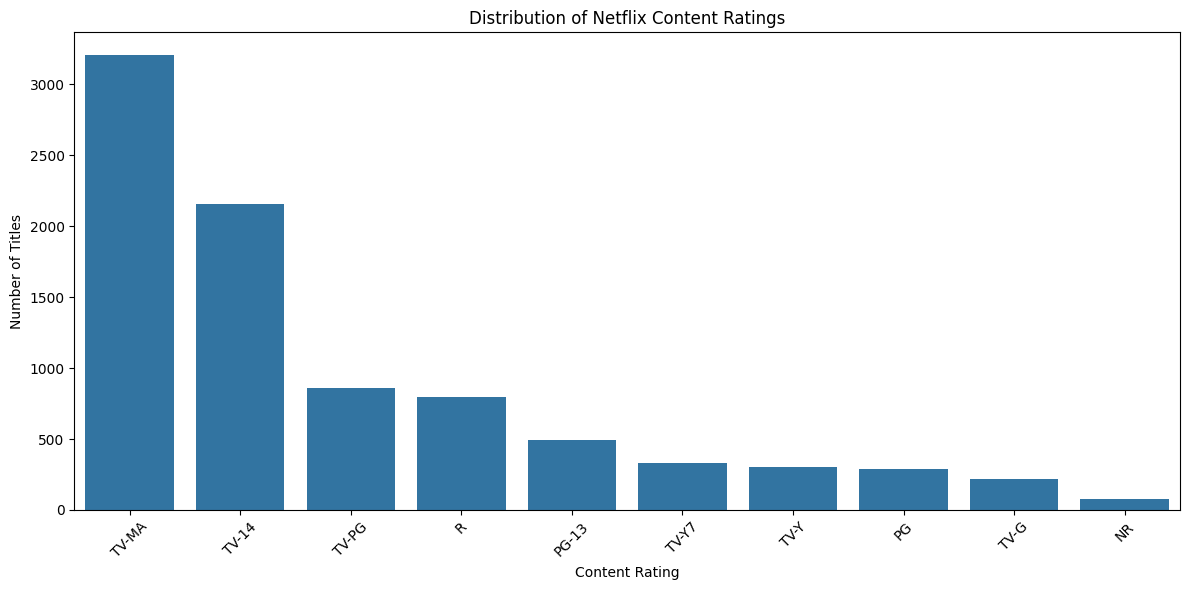

In [22]:
# Count titles by rating
rating_counts = df["rating"].value_counts().head(10)

# Display the top 10 ratings
print("Top 10 Netflix Content Ratings:")
print(rating_counts)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Movie Duration Statistics:
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64

Average Movie Duration: 99.58 minutes
Shortest Movie Duration: 3.0 minutes
Longest Movie Duration: 312.0 minutes


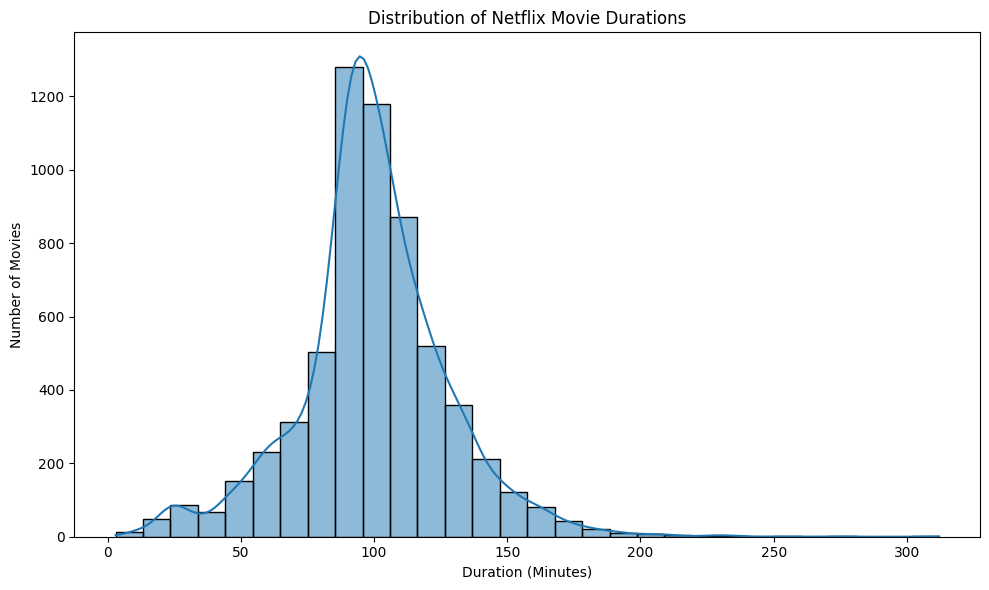

In [23]:
# Select only movies
movies = df[df["type"] == "Movie"].copy()

# Extract movie duration in minutes
movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Remove movies without valid duration information
movie_durations = movies["duration_minutes"].dropna()

# Display summary statistics
print("Movie Duration Statistics:")
print(movie_durations.describe())

print("\nAverage Movie Duration:",
      round(movie_durations.mean(), 2), "minutes")

print("Shortest Movie Duration:",
      movie_durations.min(), "minutes")

print("Longest Movie Duration:",
      movie_durations.max(), "minutes")

# Create a histogram
plt.figure(figsize=(10, 6))

sns.histplot(movie_durations, bins=30, kde=True)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

Netflix Titles Added Each Year:
year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     429
2017    1188
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


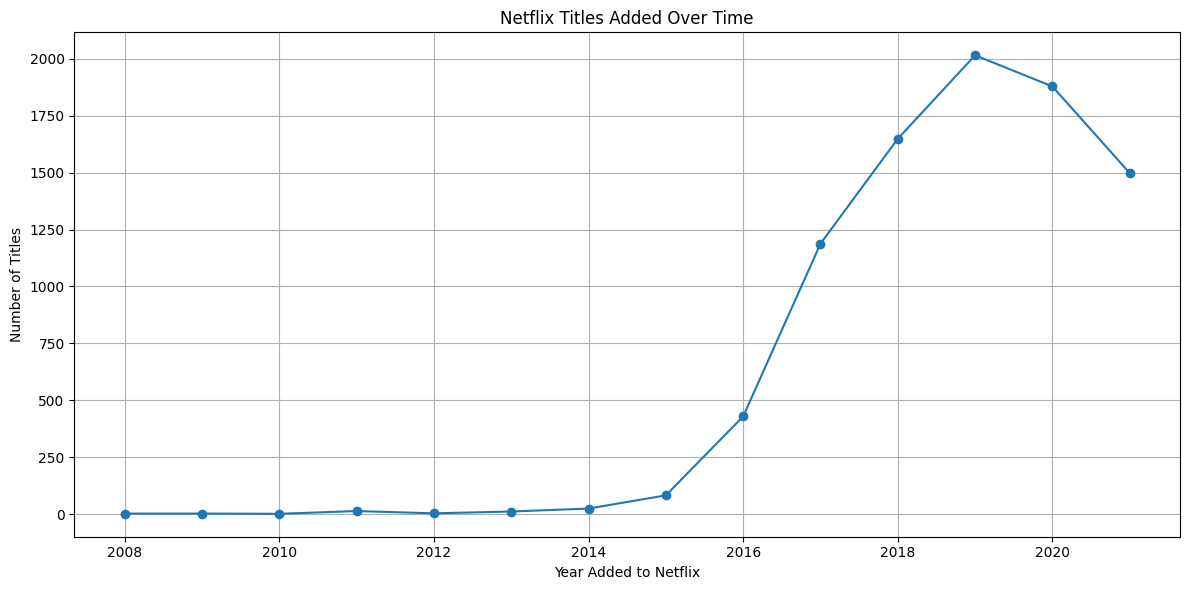

In [24]:
# Convert date_added to datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

# Extract the year in which each title was added
df["year_added"] = df["date_added"].dt.year

# Count titles added each year
added_counts = df["year_added"].value_counts().sort_index()

# Display the results
print("Netflix Titles Added Each Year:")
print(added_counts)

# Create a line chart
plt.figure(figsize=(12, 6))

plt.plot(
    added_counts.index,
    added_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added Over Time")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.tight_layout()
plt.show()

Movies and TV Shows by Release Year:
type          Movie  TV Show
release_year                
2012            173       63
2013            225       62
2014            264       88
2015            398      160
2016            658      243
2017            767      265
2018            767      379
2019            633      397
2020            517      436
2021            277      315


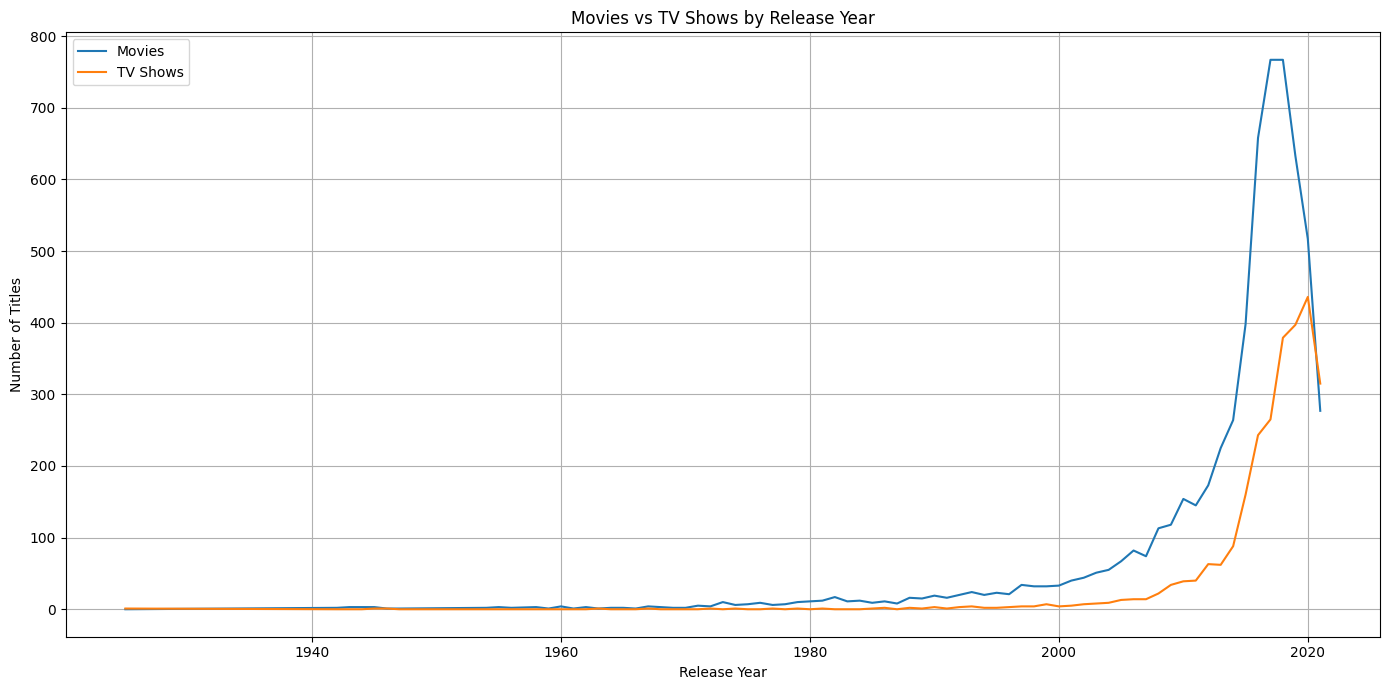

In [25]:
# Count movies and TV shows by release year
yearly_content = df.groupby(
    ["release_year", "type"]
).size().unstack(fill_value=0)

# Display the most recent 10 years in the dataset
print("Movies and TV Shows by Release Year:")
print(yearly_content.tail(10))

# Plot the comparison
plt.figure(figsize=(14, 7))

plt.plot(
    yearly_content.index,
    yearly_content.get("Movie", 0),
    label="Movies"
)

plt.plot(
    yearly_content.index,
    yearly_content.get("TV Show", 0),
    label="TV Shows"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Top 10 Directors on Netflix:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Martin Scorsese        12
Youssef Chahine        12
Jay Chapman            12
Name: count, dtype: int64


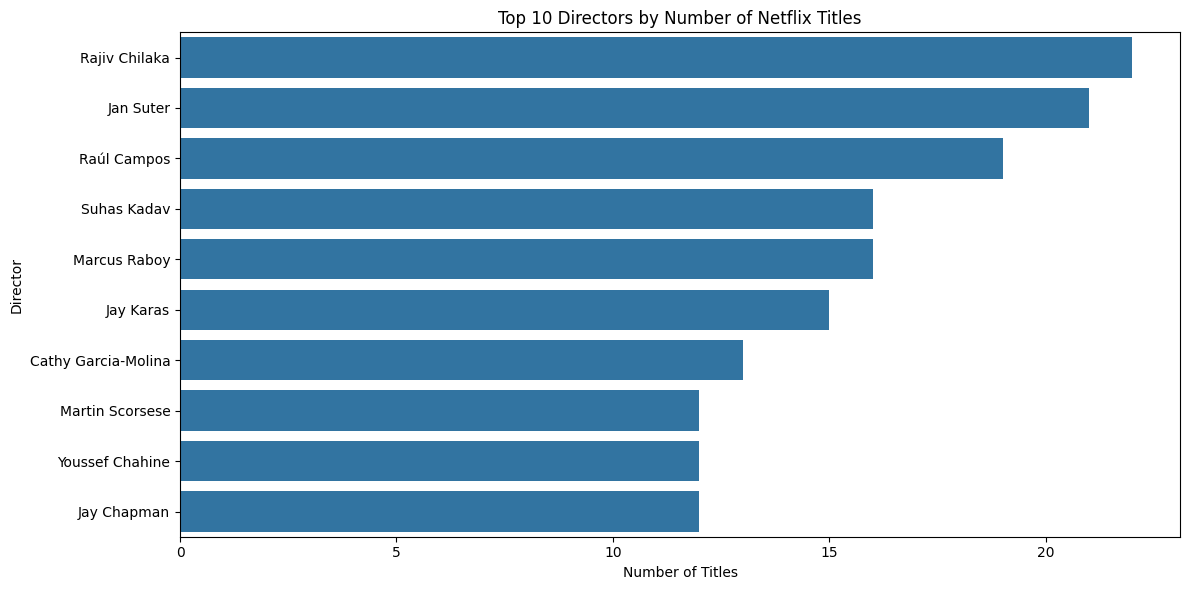

In [26]:
# Split director names and count each director
director_counts = (
    df[df["director"] != "Unknown"]["director"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

# Select the top 10 directors
top_directors = director_counts.head(10)

# Display the results
print("Top 10 Directors on Netflix:")
print(top_directors)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_directors.values,
    y=top_directors.index
)

plt.title("Top 10 Directors by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Director")

plt.tight_layout()
plt.show()

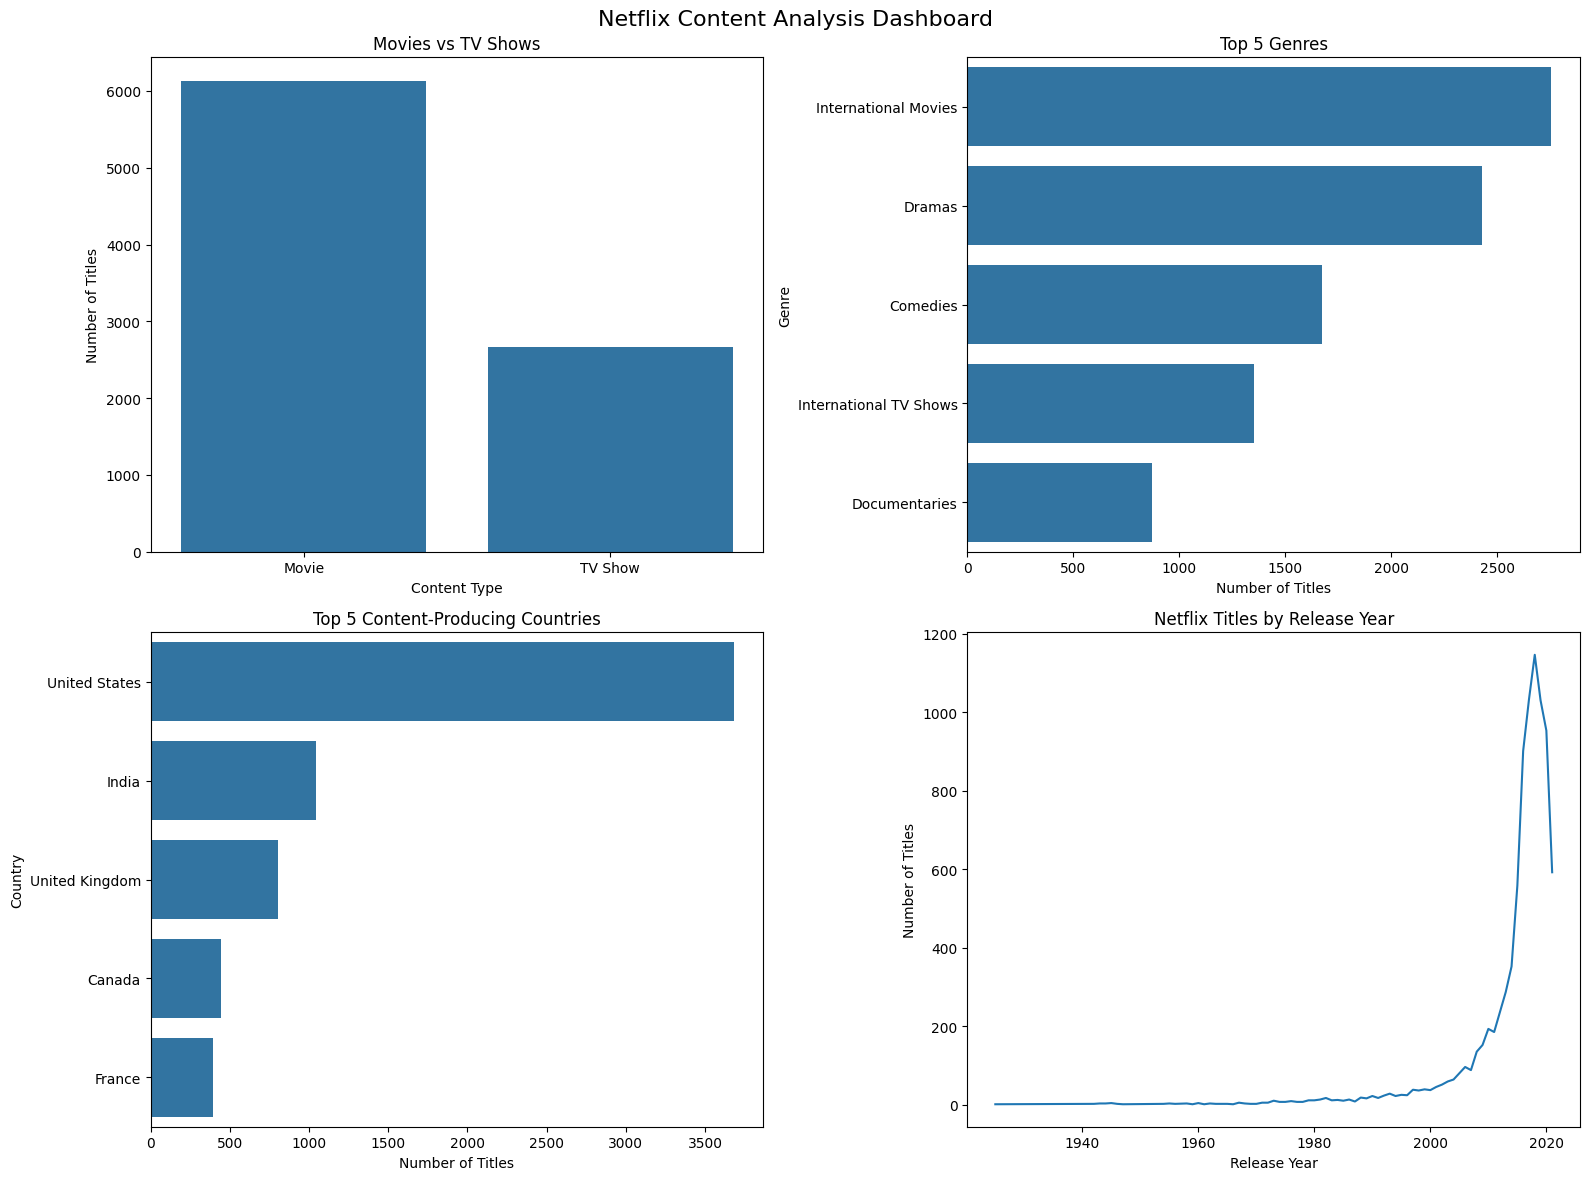

In [27]:
# Create a 2x2 visualization dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Movies vs TV Shows
content_counts = df["type"].value_counts()

sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Movies vs TV Shows")
axes[0, 0].set_xlabel("Content Type")
axes[0, 0].set_ylabel("Number of Titles")

# 2. Top 5 Genres
top_5_genres = genre_counts.head(5)

sns.barplot(
    x=top_5_genres.values,
    y=top_5_genres.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 5 Genres")
axes[0, 1].set_xlabel("Number of Titles")
axes[0, 1].set_ylabel("Genre")

# 3. Top 5 Countries
top_5_countries = country_counts.head(5)

sns.barplot(
    x=top_5_countries.values,
    y=top_5_countries.index,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 5 Content-Producing Countries")
axes[1, 0].set_xlabel("Number of Titles")
axes[1, 0].set_ylabel("Country")

# 4. Titles by Release Year
yearly_counts = df["release_year"].value_counts().sort_index()

axes[1, 1].plot(
    yearly_counts.index,
    yearly_counts.values
)

axes[1, 1].set_title("Netflix Titles by Release Year")
axes[1, 1].set_xlabel("Release Year")
axes[1, 1].set_ylabel("Number of Titles")

plt.suptitle("Netflix Content Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

In [28]:
# Calculate project statistics
total_titles = len(df)

movie_count = (df["type"] == "Movie").sum()
tv_show_count = (df["type"] == "TV Show").sum()

earliest_year = df["release_year"].min()
latest_year = df["release_year"].max()

top_genre = genre_counts.index[0]
top_country = country_counts.index[0]

average_movie_duration = movie_durations.mean()

# Display the final summary
print("=" * 50)
print("NETFLIX CONTENT VISUALIZATION - PROJECT SUMMARY")
print("=" * 50)

print(f"\nTotal Titles Analyzed: {total_titles}")
print(f"Total Movies: {movie_count}")
print(f"Total TV Shows: {tv_show_count}")

print(f"\nEarliest Release Year: {earliest_year}")
print(f"Latest Release Year: {latest_year}")

print(f"\nMost Common Genre: {top_genre}")
print(f"Country with Most Associated Titles: {top_country}")

print(
    f"\nAverage Movie Duration: "
    f"{average_movie_duration:.2f} minutes"
)

print("\nVisualizations Created:")
print("1. Movies vs TV Shows")
print("2. Titles by Release Year")
print("3. Top 10 Genres")
print("4. Top 10 Countries")
print("5. Content Ratings")
print("6. Movie Durations")
print("7. Titles Added Over Time")
print("8. Movies vs TV Shows by Release Year")
print("9. Top 10 Directors")
print("10. Summary Dashboard")

print("\nProject Status: Analysis Completed")
print("=" * 50)

NETFLIX CONTENT VISUALIZATION - PROJECT SUMMARY

Total Titles Analyzed: 8797
Total Movies: 6131
Total TV Shows: 2666

Earliest Release Year: 1925
Latest Release Year: 2021

Most Common Genre: International Movies
Country with Most Associated Titles: United States

Average Movie Duration: 99.58 minutes

Visualizations Created:
1. Movies vs TV Shows
2. Titles by Release Year
3. Top 10 Genres
4. Top 10 Countries
5. Content Ratings
6. Movie Durations
7. Titles Added Over Time
8. Movies vs TV Shows by Release Year
9. Top 10 Directors
10. Summary Dashboard

Project Status: Analysis Completed


Conclusion

This project analyzed Netflix movies and TV shows using Python and data visualization techniques.

The analysis covered:

Distribution of movies and TV shows.
Content released in different years.
Most common genres on Netflix.
Countries associated with the largest number of titles.
Distribution of content ratings.
Movie duration analysis.
Netflix content added over time.
Comparison of movies and TV shows by release year.
Directors with the most titles.
A summary dashboard combining key visualizations.
Key Learnings

Through this project, we learned how to:

Load and explore a real-world dataset using Pandas.
Identify and handle missing values.
Clean and transform data for analysis.
Group and analyze categorical data.
Create charts using Matplotlib and Seaborn.
Build a dashboard to summarize findings.
Final Outcome

The project demonstrates how Python can be used to explore a streaming platform's content library and communicate findings through data visualization.

Tools Used: Python, Pandas, NumPy, Matplotlib, Seaborn, and Google Colab.